# 01 Data wrangling: Delhi daily air quality, 2015 to 2019

**Syllabus unit:** Data wrangling (5 marks): data ingest, cleaning (missing values, duplicates, outliers).
**Output:** `data/processed/aqi_delhi_clean.csv` (the data contract every later notebook and the app read),
plus `data/processed/aqi_delhi_2020_holdout.csv`, kept aside to study the COVID-19 lockdown break.

Source: Kaggle, *Air Quality Data in India (2015 - 2020)*, file `city_day.csv` (Central Pollution Control Board data
compiled by Vopani). One row per city per day.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from src.utils import *
set_plot_style()
print("setup ok")

setup ok


## 1. Ingest and confirm the schema
The project pack asks us to confirm the file and column names after download, because Kaggle uploads can change.

In [2]:
raw = pd.read_csv(DATA_RAW, parse_dates=["Date"])
print("shape:", raw.shape)
print("columns:", list(raw.columns))
print("cities:", raw["City"].nunique(), "| dates:", raw["Date"].min().date(), "to", raw["Date"].max().date())
expected_cols = ["City", "Date"] + POLLUTANTS + ["Benzene", "Toluene", "Xylene", "AQI", "AQI_Bucket"]
assert set(expected_cols) <= set(raw.columns), "Kaggle file has changed: check the column names"
raw.head()

shape: (29531, 16)
columns: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']
cities: 26 | dates: 2015-01-01 to 2020-07-01


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
miss_all = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
miss_all.to_frame("% missing (all 26 cities)")

,% missing (all 26 cities)
Xylene,61.3
PM10,37.7
NH3,35.0
Toluene,27.2
Benzene,19.0
AQI,15.9
AQI_Bucket,15.9
PM2.5,15.6
NOx,14.2
O3,13.6


Across all cities Xylene, PM10 and NH3 are the most often missing columns; Benzene, Toluene and Xylene are aromatic
hydrocarbons that do **not** enter the Indian AQI formula. They are dropped as planned, so the project keeps the
nine AQI-relevant pollutants.

## 2. Filter the city and the study window
Delhi has the longest daily record and the strongest winter smog cycle. The window 2015-01-01 to 2019-12-31 keeps
five complete years; 2020 is held out because the COVID-19 lockdown (from 25 March 2020) is a structural break.

In [4]:
delhi_all = raw[raw["City"] == CITY].drop(columns=["City", "Benzene", "Toluene", "Xylene"]).sort_values("Date")
print("duplicate (City, Date) rows:", raw.duplicated(["City", "Date"]).sum())
print("fully duplicated rows      :", raw.duplicated().sum())

df = delhi_all[delhi_all["Date"].between(WINDOW_START, WINDOW_END)].set_index("Date")
hold = delhi_all[delhi_all["Date"] > WINDOW_END].set_index("Date")
full_range = pd.date_range(WINDOW_START, WINDOW_END, freq="D")
missing_days = full_range.difference(df.index)
print(f"study window rows: {len(df)} | calendar days: {len(full_range)} | missing calendar days: {len(missing_days)}")
print(f"2020 hold-out rows: {len(hold)} ({hold.index.min().date()} to {hold.index.max().date()})")
df = df.reindex(full_range)
df.index.name = "Date"

duplicate (City, Date) rows: 0
fully duplicated rows      : 0
study window rows: 1826 | calendar days: 1826 | missing calendar days: 0
2020 hold-out rows: 183 (2020-01-01 to 2020-07-01)


There are no duplicate rows and no missing calendar days, so the series is a complete daily calendar of 1,826 days.

## 3. Missing values: profile and hidden missing values
A careful check finds missing values that are *not* coded as NaN: CO is exactly 0 on many days, which is
physically impossible in a city of 20 million vehicles.

In [5]:
NUM = POLLUTANTS + ["AQI"]
zeros = (df[NUM] == 0).sum()
print("exact zeros per column:\n", zeros[zeros > 0])
co_zero_months = df.index[df["CO"] == 0].to_period("M").value_counts().sort_index()
print("\nmonths with CO == 0:\n", co_zero_months)
df.loc[df["NOx"] == 0, ["NO", "NO2", "NOx"]]

exact zeros per column:
 NOx     2
CO     87
dtype: int64

months with CO == 0:
 Date
2017-02     2
2017-04     1
2017-06    23
2017-07    31
2017-08    30
Freq: M, Name: count, dtype: int64


,NO,NO2,NOx
Date,,,
2017-08-12,NaN,NaN,0.0
2017-08-13,NaN,NaN,0.0


**Finding.** CO reads exactly 0 for almost all of June to August 2017 (84 days in a row) and NOx is 0 on two days
when NO and NO2 are missing. These are instrument outages recorded as zero, not clean air, so they are converted to
missing values before imputation. Treating them as real would bias every CO coefficient downstream.

In [6]:
df.loc[df["CO"] == 0, "CO"] = np.nan
df.loc[df["NOx"] == 0, "NOx"] = np.nan

def gap_profile(s: pd.Series) -> dict:
    na = s.isna()
    runs = (na != na.shift()).cumsum()[na].value_counts()
    return {"missing": int(na.sum()), "% missing": round(na.mean() * 100, 1),
            "gaps": int(len(runs)), "longest gap (days)": int(runs.max()) if len(runs) else 0}

gaps = pd.DataFrame({c: gap_profile(df[c]) for c in NUM}).T
save_table(gaps.reset_index(names="Variable"), "missing_value_profile")
gaps

,missing,% missing,gaps,longest gap (days)
PM2.5,2.0,0.1,1.0,2.0
PM10,77.0,4.2,9.0,58.0
NO,2.0,0.1,1.0,2.0
NO2,2.0,0.1,1.0,2.0
NOx,2.0,0.1,1.0,2.0
NH3,9.0,0.5,5.0,2.0
CO,87.0,4.8,3.0,84.0
SO2,110.0,6.0,3.0,81.0
O3,84.0,4.6,3.0,81.0
AQI,10.0,0.5,5.0,4.0


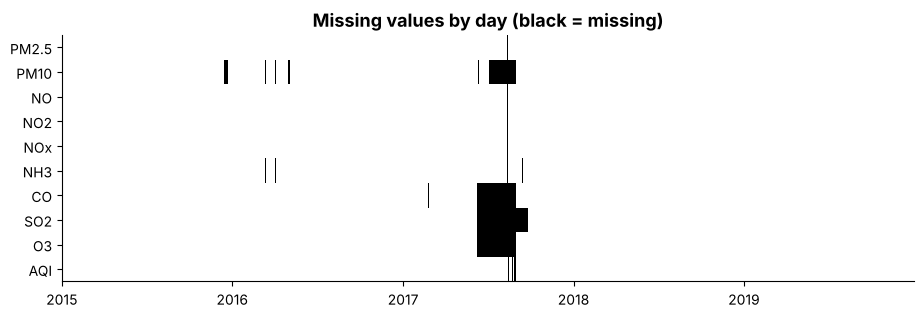

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.imshow(df[NUM].isna().T.values, aspect="auto", cmap="Greys", interpolation="nearest",
          extent=[0, len(df), len(NUM) - 0.5, -0.5])
ax.set_yticks(range(len(NUM)), NUM)
ticks = [df.index.get_loc(pd.Timestamp(f"{y}-01-01")) for y in range(2015, 2020)]
ax.set_xticks(ticks, range(2015, 2020))
ax.set_title("Missing values by day (black = missing)")
ax.grid(False)
save_figure(fig, "01_missing_map")
plt.show()

Most gaps are one or two days long, but PM10, SO2, O3 and CO each have one long block (58 to 84 days). Short
gaps and long gaps need different treatment: a straight line between neighbouring days is fine for a 2-day gap, but
a straight line across a whole season would erase the seasonal cycle.

## 4. Choosing the imputation method by experiment
Rather than assume a method, we hide values that we *do* know and score three candidate methods on how well they
recover them (RMSE on the original scale):

1. **Linear interpolation in time**
2. **Calendar-month median** (the typical value for that month across the five years)
3. **Iterative (MICE-style) imputation**: each pollutant is regressed on the other pollutants plus a seasonal
   signal (sine and cosine of day-of-year) using Bayesian ridge regression. AQI is deliberately **excluded** from
   the predictors so the targets do not leak into the features.

The test is run twice: short gaps (random 2-day holes) and long gaps (a 60-day block), repeated over 20 seeds.

In [8]:
doy = df.index.dayofyear.values
season_feats = pd.DataFrame({"sin_doy": np.sin(2 * np.pi * doy / 365.25),
                             "cos_doy": np.cos(2 * np.pi * doy / 365.25)}, index=df.index)

def impute_interp(d):
    return d.interpolate(method="time", limit_direction="both")

def impute_month(d):
    out = d.copy()
    for c in d.columns:
        out[c] = out[c].fillna(d.groupby(d.index.month)[c].transform("median"))
    return out

def impute_mice(d, seed=SEED):
    X = pd.concat([np.log1p(d), season_feats.loc[d.index]], axis=1)   # log scale: pollutants are skewed
    imp = IterativeImputer(estimator=BayesianRidge(), max_iter=25, random_state=seed, sample_posterior=False)
    Z = pd.DataFrame(imp.fit_transform(X), index=d.index, columns=X.columns)
    return np.expm1(Z[d.columns]).clip(lower=d.min(), upper=d.max(), axis=1)   # stay inside the observed range

METHODS = {"Linear interpolation": impute_interp, "Calendar-month median": impute_month,
           "Iterative (MICE)": impute_mice}
base = df[POLLUTANTS]

def mask_experiment(kind: str, n_rep: int = 20) -> pd.DataFrame:
    rows = []
    for rep in range(n_rep):
        rng = np.random.default_rng(1000 + rep)
        for col in ["PM2.5", "PM10", "NO2", "SO2", "O3", "CO"]:
            known = base[col].dropna().index
            if kind == "short":
                starts = rng.choice(len(known) - 2, 30, replace=False)
                idx = known[np.unique(np.concatenate([starts, starts + 1]))]
            else:
                st0 = rng.integers(0, len(known) - 60)
                idx = known[st0:st0 + 60]
            d = base.copy()
            truth = d.loc[idx, col].copy()
            d.loc[idx, col] = np.nan
            for name, f in METHODS.items():
                est = f(d).loc[idx, col]
                rmse = float(np.sqrt(np.mean((est - truth) ** 2)))
                rows.append({"gap": kind, "pollutant": col, "method": name, "rep": rep,
                             "nRMSE": rmse / truth.std()})
    return pd.DataFrame(rows)

exp = pd.concat([mask_experiment("short"), mask_experiment("long")])
summary_imp = (exp.groupby(["gap", "method"])["nRMSE"].agg(["mean", "std"]).round(3)
               .unstack("gap"))
save_table(summary_imp.reset_index(), "imputation_experiment")
summary_imp

mean           std       
gap                     long  short   long  short
method                                           
Calendar-month median  1.299  0.876  0.553  0.155
Iterative (MICE)       1.079  0.626  0.649  0.206
Linear interpolation   1.266  0.484  0.492  0.112

In [9]:
exp.groupby(["gap", "pollutant", "method"])["nRMSE"].mean().unstack("method").round(2)

method           Calendar-month median  Iterative (MICE)  Linear interpolation
gap   pollutant                                                               
long  CO                          1.45              1.67                  1.20
      NO2                         1.37              0.79                  1.42
      O3                          1.50              1.36                  1.17
      PM10                        1.07              0.75                  1.34
      PM2.5                       0.99              0.68                  1.15
      SO2                         1.42              1.21                  1.32
short CO                          1.04              0.89                  0.39
      NO2                         0.86              0.51                  0.53
      O3                          1.04              0.81                  0.49
      PM10                        0.79              0.48                  0.52
      PM2.5                       0.65              0.44                  0.51
      SO2                         0.88              0.63                  0.48

The error is reported as *normalised RMSE* (RMSE divided by the standard deviation of the hidden values), so a
value of 1 means "no better than guessing the average of those days".

**Findings.**
* **Short gaps:** linear interpolation is best overall (mean nRMSE about 0.48, against 0.63 for MICE and 0.88 for
  the monthly median). Air quality is strongly persistent from one day to the next, so the neighbours are the best
  guide. For PM2.5 and PM10 the MICE model is slightly better, because the two particulate series move together.
* **Long gaps:** every method is close to or above 1, so a two-month outage cannot be recovered precisely by any
  method. That is an honest limit of the data. MICE is best on average (about 1.08) and clearly best for PM2.5,
  PM10 and NO2, where other pollutants carry information; interpolation is better for CO and O3.

Because no single method wins everywhere, the method is chosen **per pollutant and per gap type** from this
experiment (the rule is coded, so it follows the evidence if the data change). Pollutants that were not in the
experiment (NO, NOx, NH3: only 1-2 day gaps) use the overall short-gap winner.

In [10]:
best_overall = exp.groupby(["gap", "method"])["nRMSE"].mean()
best_by = exp.groupby(["gap", "pollutant", "method"])["nRMSE"].mean().groupby(["gap", "pollutant"]).idxmin()
choice = {}
for c in POLLUTANTS:
    choice[c] = {}
    for g in ("short", "long"):
        key = (g, c)
        choice[c][g] = best_by[key][2] if key in best_by.index else best_overall[g].idxmin()
SHORT_LIMIT = 7   # days; gaps up to a week count as short
choice_tab = pd.DataFrame(choice).T.rename(columns={"short": f"gap <= {SHORT_LIMIT} days", "long": "longer gap"})
save_table(choice_tab.reset_index(names="Pollutant"), "imputation_choice")
choice_tab

,gap <= 7 days,longer gap
PM2.5,Iterative (MICE),Iterative (MICE)
PM10,Iterative (MICE),Iterative (MICE)
NO,Linear interpolation,Iterative (MICE)
NO2,Iterative (MICE),Iterative (MICE)
NOx,Linear interpolation,Iterative (MICE)
NH3,Linear interpolation,Iterative (MICE)
CO,Linear interpolation,Linear interpolation
SO2,Linear interpolation,Iterative (MICE)
O3,Linear interpolation,Linear interpolation


## 5. Apply the imputation
Each gap uses the method chosen above for its pollutant and length. Every imputed cell is
recorded in an `Imputed` count column so later notebooks can check sensitivity. AQI itself (10 missing days, longest
gap 4 days) is interpolated in time, never predicted from the pollutants, so the target is not manufactured from
the features.

In [11]:
def run_lengths(s: pd.Series) -> pd.Series:
    na = s.isna()
    grp = (na != na.shift()).cumsum()
    return na.groupby(grp).transform("sum").where(na, 0)

clean = df.copy()
was_missing = clean[NUM].isna()
filled = {name: f(clean[POLLUTANTS]) for name, f in METHODS.items()}   # every method on the real gaps
for c in POLLUTANTS:
    L = run_lengths(clean[c])
    short_mask = (L > 0) & (L <= SHORT_LIMIT)
    long_mask = L > SHORT_LIMIT
    clean.loc[short_mask, c] = filled[choice[c]["short"]].loc[short_mask, c]
    clean.loc[long_mask, c] = filled[choice[c]["long"]].loc[long_mask, c]
clean["AQI"] = clean["AQI"].interpolate(method="time", limit_direction="both").round()
clean["Imputed"] = was_missing.sum(axis=1)
print("missing after imputation:", int(clean[NUM].isna().sum().sum()))
print("days with at least one imputed value:", int((clean["Imputed"] > 0).sum()))

missing after imputation: 0
days with at least one imputed value: 130


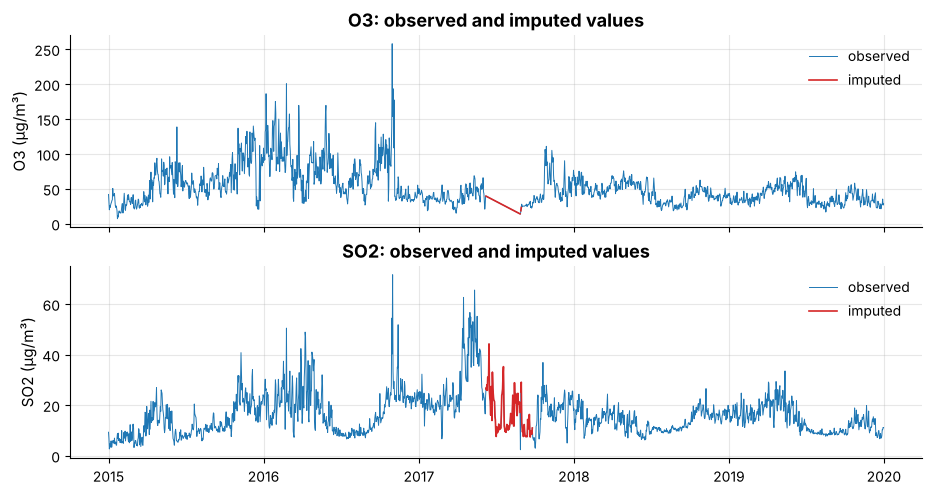

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, c in zip(axes, ["O3", "SO2"]):
    ax.plot(clean.index, clean[c], lw=.7, color="C0", label="observed")
    ax.plot(clean.index, clean[c].where(was_missing[c]), lw=1.2, color="C3", label="imputed")
    ax.set(ylabel=f"{c} (µg/m³)", title=f"{c}: observed and imputed values")
    ax.legend(loc="upper right")
save_figure(fig, "01_imputed_series")
plt.show()

The imputed stretches (red) follow the seasonal level of the surrounding data instead of a flat line.

## 6. Outliers: detect, judge, treat
Two detectors are used:

* **IQR rule** (beyond Q1 - 1.5 IQR or Q3 + 1.5 IQR) - the textbook screen;
* **Hampel filter** (more than 4 robust standard deviations from the centred 15-day rolling median) - this finds
  isolated *spikes* relative to the local season rather than days that are just high because it is winter.

In [13]:
q1, q3 = clean[NUM].quantile(.25), clean[NUM].quantile(.75)
iqr_flags = (clean[NUM] < q1 - 1.5 * (q3 - q1)) | (clean[NUM] > q3 + 1.5 * (q3 - q1))

def hampel(s, window=15, k=4.0):
    med = s.rolling(window, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=5).median() * 1.4826
    return (s - med).abs() > k * mad.replace(0, np.nan)

hampel_flags = clean[NUM].apply(hampel).fillna(False)
outlier_tab = pd.DataFrame({"IQR outliers": iqr_flags.sum(), "Hampel spikes": hampel_flags.sum(),
                            "% IQR": (iqr_flags.mean() * 100).round(1)})
outlier_tab

,IQR outliers,Hampel spikes,% IQR
PM2.5,61,23,3.3
PM10,18,23,1.0
NO,112,32,6.1
NO2,43,19,2.4
NOx,72,16,3.9
NH3,74,30,4.1
CO,177,21,9.7
SO2,57,24,3.1
O3,89,28,4.9
AQI,6,27,0.3


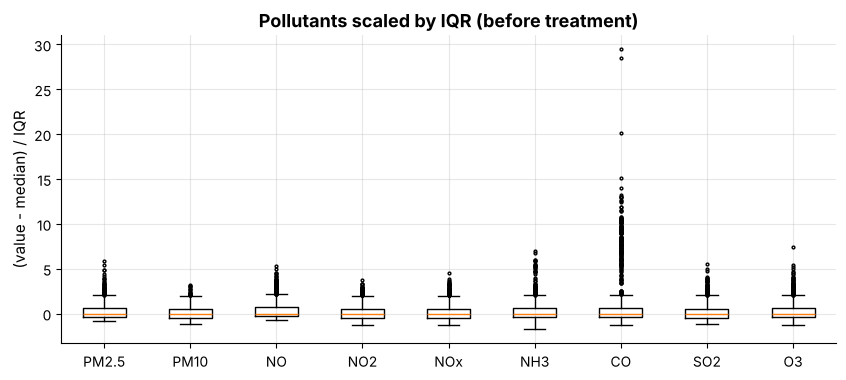

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
z = (clean[POLLUTANTS] - clean[POLLUTANTS].median()) / (q3 - q1)[POLLUTANTS]
ax.boxplot([z[c] for c in POLLUTANTS], tick_labels=POLLUTANTS, flierprops={"markersize": 2})
ax.set(title="Pollutants scaled by IQR (before treatment)", ylabel="(value - median) / IQR")
save_figure(fig, "01_outlier_boxplots")
plt.show()

In [15]:
iqr_by_season = iqr_flags.groupby(clean.index.month.map(season_of)).mean().mul(100).round(1)
iqr_by_season[["PM2.5", "PM10", "CO", "AQI"]]

,PM2.5,PM10,CO,AQI
Date,,,,
Monsoon,0.0,0.5,2.5,0.0
Post-monsoon,11.1,3.0,0.3,2.0
Summer,0.0,0.0,20.0,0.0
Winter,6.0,1.3,15.3,0.0


**Judgement.** Most IQR outliers are winter and post-monsoon smog days (see the season table above), and they are
exactly the events this project is about: deleting them would erase the severe-pollution days. So:

* **AQI is never altered.** Extreme AQI days are real and are the target.
* **Pollutant readings are winsorised** at their 0.5th and 99.5th percentiles. This trims only the most extreme
  sensor values (for example CO of 30 mg/m³ in December 2015, when the AQI that day was only about 313, which is
  inconsistent with a CO sub-index that would be "Severe") while keeping their rank as high days. It limits the
  leverage of a handful of points on regression coefficients.
* Hampel spikes are flagged in a `Spike_Flag` column for transparency, not deleted.

In [16]:
lo_cap = clean[POLLUTANTS].quantile(.005)
hi_cap = clean[POLLUTANTS].quantile(.995)
before = clean[POLLUTANTS].copy()
clean[POLLUTANTS] = clean[POLLUTANTS].clip(lower=lo_cap, upper=hi_cap, axis=1)
changed = (before != clean[POLLUTANTS]).sum()
caps = pd.DataFrame({"lower cap": lo_cap.round(2), "upper cap": hi_cap.round(2), "values changed": changed})
clean["Spike_Flag"] = hampel_flags[POLLUTANTS].any(axis=1).astype(int)
save_table(caps.reset_index(names="Pollutant"), "winsorisation_caps")
caps

,lower cap,upper cap,values changed
PM2.5,16.93,463.35,20
PM10,39.76,621.72,20
NO,5.27,167.59,20
NO2,16.52,133.87,20
NOx,2.60,196.66,20
NH3,15.66,136.22,20
CO,0.24,13.78,19
SO2,3.68,52.84,20
O3,14.93,159.73,20


## 7. Derived columns and the two targets
All rules come from `src/utils.py` so the notebooks and the app cannot disagree.

| Column | Rule |
| --- | --- |
| `AQI_Bucket` | Indian AQI bands: Good 0-50, Satisfactory 51-100, Moderate 101-200, Poor 201-300, Very Poor 301-400, Severe 401+ |
| `Season` | Winter Dec-Feb, Summer Mar-May, Monsoon Jun-Sep, Post-monsoon Oct-Nov (IMD seasons) |
| `Poor_Flag` | 1 if AQI > 200 |
| `AQI_Group` | Low (≤100), Moderate (101-200), High (>200) |

In [17]:
def add_derived(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["AQI_Bucket"] = d["AQI"].map(aqi_bucket)
    d["Year"] = d.index.year
    d["Month"] = d.index.month
    d["Season"] = d["Month"].map(season_of)
    d["Poor_Flag"] = d["AQI"].map(poor_flag)
    d["AQI_Group"] = d["AQI"].map(aqi_group)
    return d

orig_bucket = df["AQI_Bucket"]
clean = add_derived(clean)
agree = (orig_bucket.dropna() == clean.loc[orig_bucket.dropna().index, "AQI_Bucket"]).mean()
print(f"recomputed AQI_Bucket agrees with Kaggle's on {agree:.1%} of the days where Kaggle gave one")
out = clean.reset_index()[CONTRACT_COLUMNS + ["Imputed", "Spike_Flag"]]
out[POLLUTANTS] = out[POLLUTANTS].round(2)
DATA_CLEAN.parent.mkdir(parents=True, exist_ok=True)
out.to_csv(DATA_CLEAN, index=False)
print("saved", DATA_CLEAN.relative_to(ROOT), out.shape)
out.head()

recomputed AQI_Bucket agrees with Kaggle's on 100.0% of the days where Kaggle gave one
saved data/processed/aqi_delhi_clean.csv (1826, 19)


,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI,AQI_Bucket,Year,Month,Season,Poor_Flag,AQI_Group,Imputed,Spike_Flag
0,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,13.78,9.25,41.68,472.0,Severe,2015,1,Winter,1,High,0,1
1,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,454.0,Severe,2015,1,Winter,1,High,0,1
2,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,3.68,19.71,143.0,Moderate,2015,1,Winter,0,Moderate,0,1
3,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,319.0,Very Poor,2015,1,Winter,1,High,0,0
4,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.68,23.20,325.0,Very Poor,2015,1,Winter,1,High,0,0


## 8. The 2020 hold-out (not used to fit any model)
The same cleaning is applied to January to July 2020 (gaps only by interpolation, caps from the 2015-2019
data) so notebook 05 can compare the forecast with what actually happened during the lockdown.

In [18]:
h = hold.copy()
h.loc[h["CO"] == 0, "CO"] = np.nan
h[NUM] = h[NUM].interpolate(method="time", limit_direction="both")
h[POLLUTANTS] = h[POLLUTANTS].clip(lower=lo_cap, upper=hi_cap, axis=1)
h["AQI"] = h["AQI"].round()
h = add_derived(h)
h.reset_index()[CONTRACT_COLUMNS].to_csv(DATA_2020, index=False)
print("saved", DATA_2020.relative_to(ROOT), h.shape)
h.resample("MS")["AQI"].mean().round(1).to_frame("mean AQI")

saved data/processed/aqi_delhi_2020_holdout.csv (183, 16)


,mean AQI
Date,
2020-01-01,308.5
2020-02-01,262.1
2020-03-01,135.8
2020-04-01,113.0
2020-05-01,148.6
2020-06-01,125.7
2020-07-01,101.0


## 9. Contract check
`src/check_contract.py` verifies the cleaned file: complete daily calendar, no missing values, non-negative
pollutants, and every derived column recomputed from its rule.

In [19]:
import subprocess
res = subprocess.run([sys.executable, str(ROOT / "src" / "check_contract.py")], capture_output=True, text=True)
print(res.stdout)
assert res.returncode == 0, "contract check failed"

Checking /home/claude/aqi-project/data/processed/aqi_delhi_clean.csv

  [PASS] all contract columns present
  [PASS] every Date parses
  [PASS] Date sorted ascending
  [PASS] no duplicate dates
  [PASS] daily dates 2015-01-01 to 2019-12-31 with no gaps
  [PASS] no missing values in pollutants and AQI
  [PASS] pollutants are zero or more
  [PASS] AQI above zero
  [PASS] AQI_Bucket values valid
  [PASS] no missing AQI_Bucket
  [PASS] AQI_Bucket agrees with AQI bands
  [PASS] Month is 1 to 12
  [PASS] Month matches Date
  [PASS] Year matches Date
  [PASS] Season values valid
  [PASS] Season matches Month
  [PASS] Poor_Flag is 0 or 1
  [PASS] Poor_Flag equals AQI above 200
  [PASS] AQI_Group values valid
  [PASS] AQI_Group matches AQI

RESULT: PASS (0 warnings)



## 10. Wrangling summary

| Step | Decision | Why |
| --- | --- | --- |
| Columns | Dropped Benzene, Toluene, Xylene | Not in the Indian AQI formula; Xylene mostly missing |
| Window | Delhi, 2015-01-01 to 2019-12-31 (1,826 days); 2020 held out | Five full years; lockdown is a structural break |
| Duplicates | None found | Checked on (City, Date) and on full rows |
| Hidden missing | CO = 0 (Jun-Aug 2017) and NOx = 0 recoded as missing | Sensor outages, physically impossible zeros |
| Short gaps (≤7 days) | Mostly linear interpolation (MICE for PM2.5, PM10, NO2), chosen by masked-value experiment | Lowest recovery error; day-to-day persistence |
| Long gaps (>7 days) | MICE for PM2.5, PM10, NO2, SO2; interpolation for CO, O3, chosen by experiment | Best of three; long outages remain uncertain (flagged in `Imputed`) |
| AQI gaps | Time interpolation only | Avoids manufacturing the target from the features |
| Outliers | Pollutants winsorised at 0.5/99.5 percentiles; AQI untouched; spikes flagged | Severe-smog days are real and are the point of the study |
| Derived | AQI_Bucket, Year, Month, Season, Poor_Flag, AQI_Group | One rule set in `src/utils.py` |